<a href="https://colab.research.google.com/github/inamoorata/PCD_Assignment03/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pengolahan Citra Digital Assignment 03 : Morphological
Processing

In [29]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(72)

Membaca citra dan mengonversi ke grayscale untuk citra berwarna dengan rumus luminansi. Gambar yang terlalu besar diperkecil

In [30]:
def convert_grayscale(file_path, max_size=800):
    img = plt.imread(file_path)

    #PNG dibaca sbg float 0-1 diubah ke 0-255
    if img.dtype != np.uint8:
        img = (img * 255).astype(np.uint8)

    if img.ndim == 3:
        r = img[:, :, 0].astype(np.float64)
        g = img[:, :, 1].astype(np.float64)
        b = img[:, :, 2].astype(np.float64)
        gray = (0.299 * r + 0.587 * g + 0.114 * b).astype(np.uint8)
    else:
        gray = img

    #memperkecil jika terlalu besar
    step = int(np.ceil(max(gray.shape) / max_size))
    if step > 1:
        gray = gray[::step, ::step]
    return gray

Segmentasi dengan Otsu Thresholding

In [31]:
def manual_histogram(img):
    hist = np.zeros(256, dtype=np.int64)
    for v in img.ravel():
        hist[v] += 1
    return hist

def otsu_thresholding(img, invert=True):
  hist = manual_histogram(img)
  total = img.size
  sum_total = sum(t * hist[t] for t in range(256))

  best_var, threshold = -1.0, 0
  w_bg, sum_bg = 0, 0
  for t in range(256):
        w_bg += hist[t]
        if w_bg == 0:
            continue
        w_fg = total - w_bg
        if w_fg == 0:
            break
        sum_bg += t * hist[t]
        mean_bg = sum_bg / w_bg
        mean_fg = (sum_total - sum_bg) / w_fg
        var_between = w_bg * w_fg * (mean_bg - mean_fg) ** 2
        if var_between > best_var:
            best_var, threshold = var_between, t

  bright = (img > threshold).astype(np.uint8)
  binary = 1 - bright if invert else bright
  return binary, threshold

Simulasi noise dengan Salt & Pepper Noise.
Gambar asli biasanya terdapat noise.

In [32]:
def saltpepper_noise(binary_img, noise_ratio=0.04):
    noisy = binary_img.copy()
    h, w = noisy.shape
    num_noise = int(noise_ratio * h * w)
    for _ in range(num_noise // 2):                       # salt (1)
        noisy[np.random.randint(0, h), np.random.randint(0, w)] = 1
    for _ in range(num_noise // 2):                       # pepper (0)
        noisy[np.random.randint(0, h), np.random.randint(0, w)] = 0
    return noisy

Operasi Morfologi: Erosion, Dilation, Opening, Closing

In [33]:
def zero_pad(img, pad): #zero padding
    h, w = img.shape
    out = np.zeros((h + 2 * pad, w + 2 * pad), dtype=np.uint8)
    out[pad:pad + h, pad:pad + w] = img
    return out

def erosion(binary_img, kernel_size=3):
    h, w = binary_img.shape
    padded = zero_pad(binary_img, kernel_size // 2)
    out = np.ones((h, w), dtype=np.uint8)
    for i in range(kernel_size):
        for j in range(kernel_size):
            out &= padded[i:i + h, j:j + w] #semua tetangga harus 1
    return out

def dilation(binary_img, kernel_size=3):
    h, w = binary_img.shape
    padded = zero_pad(binary_img, kernel_size // 2)
    out = np.zeros((h, w), dtype=np.uint8)
    for i in range(kernel_size):
        for j in range(kernel_size):
            out |= padded[i:i + h, j:j + w] #cukup satu tetangga = 1
    return out

def opening(binary_img, kernel_size=3):
    return dilation(erosion(binary_img, kernel_size), kernel_size)

def closing(binary_img, kernel_size=3):
    return erosion(dilation(binary_img, kernel_size), kernel_size)

def opening_closing(binary_img, kernel_size=3):
    return closing(opening(binary_img, kernel_size), kernel_size)

Metrik IoU dan Akurasi serta menghitung jumlah Objek

In [34]:
def calculate_metrics(pred, reference):
    inter = np.logical_and(pred == 1, reference == 1).sum()
    union = np.logical_or(pred == 1, reference == 1).sum()
    iou = inter / union if union != 0 else 1.0
    acc = (pred == reference).sum() / pred.size
    return iou, acc

def count_objects(binary_img, min_area=1):
  h, w = binary_img.shape
  visited = np.zeros((h, w), dtype=bool)
  count = 0
  for y in range(h):
        for x in range(w):
            if binary_img[y, x] == 1 and not visited[y, x]:
                stack = [(y, x)]
                visited[y, x] = True
                area = 0
                while stack:
                    cy, cx = stack.pop()
                    area += 1
                    for dy in (-1, 0, 1):
                        for dx in (-1, 0, 1):
                            ny, nx = cy + dy, cx + dx
                            if (0 <= ny < h and 0 <= nx < w
                                    and binary_img[ny, nx] == 1 and not visited[ny, nx]):
                                visited[ny, nx] = True
                                stack.append((ny, nx))
                if area >= min_area:
                    count += 1
  return count

Eksekusi serta Visualisasi



camera.jpg, Otsu T=96, kernel 3x3
 Ground Truth = hasil Otsu tanpa noise
------------------------------------------------------------------------------
Metode                                 | IoU     | Akurasi  | Objek(>=20px)
------------------------------------------------------------------------------
Tanpa morfologi (noisy)                | 0.8858  |  98.02%  | 1            
Erosion                                | 0.7735  |  96.45%  | 2            
Dilation                               | 0.5204  |  85.58%  | 427          
Opening                                | 0.9589  |  99.36%  | 5            
Closing                                | 0.8788  |  97.85%  | 1            
Otsu Noise + Opening + Closing         | 0.9760  |  99.62%  | 4            
Otsu bersih + Open + Close (no noise)  | 0.9820  |  99.72%  | 5            




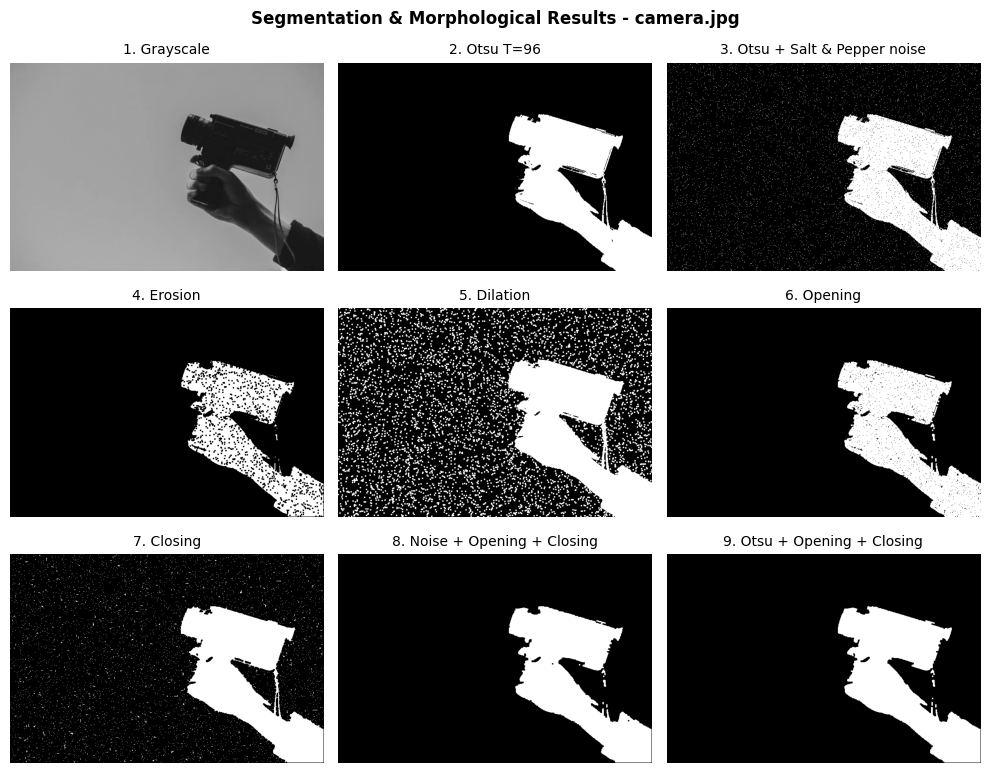



bird.jpg, Otsu T=115, kernel 3x3
 Ground Truth = hasil Otsu tanpa noise
------------------------------------------------------------------------------
Metode                                 | IoU     | Akurasi  | Objek(>=20px)
------------------------------------------------------------------------------
Tanpa morfologi (noisy)                | 0.8983  |  98.05%  | 8            
Erosion                                | 0.5456  |  92.01%  | 55           
Dilation                               | 0.5037  |  82.67%  | 393          
Opening                                | 0.8383  |  97.15%  | 67           
Closing                                | 0.7914  |  95.37%  | 7            
Otsu Noise + Opening + Closing         | 0.8353  |  97.00%  | 27           
Otsu bersih + Open + Close (no noise)  | 0.8520  |  97.29%  | 25           




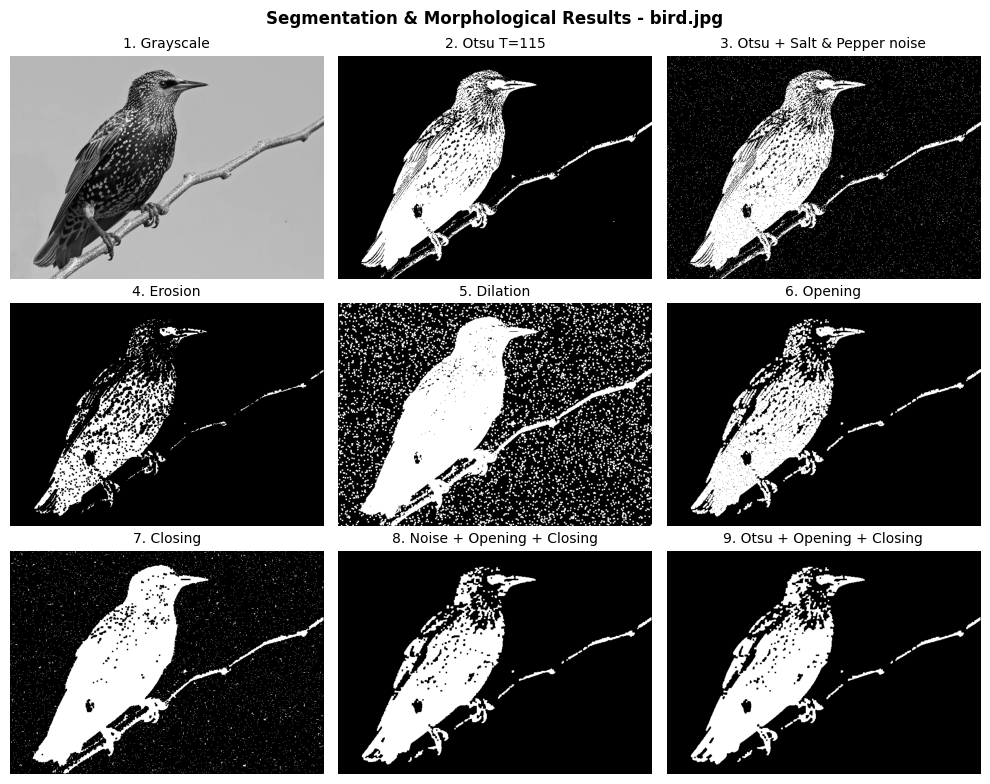



eiffel.jpg, Otsu T=116, kernel 3x3
 Ground Truth = hasil Otsu tanpa noise
------------------------------------------------------------------------------
Metode                                 | IoU     | Akurasi  | Objek(>=20px)
------------------------------------------------------------------------------
Tanpa morfologi (noisy)                | 0.9498  |  98.04%  | 2            
Erosion                                | 0.6505  |  86.79%  | 25           
Dilation                               | 0.7322  |  86.18%  | 184          
Opening                                | 0.9088  |  96.55%  | 12           
Closing                                | 0.8931  |  95.50%  | 1            
Otsu Noise + Opening + Closing         | 0.9110  |  96.54%  | 11           
Otsu bersih + Open + Close (no noise)  | 0.9188  |  96.84%  | 10           




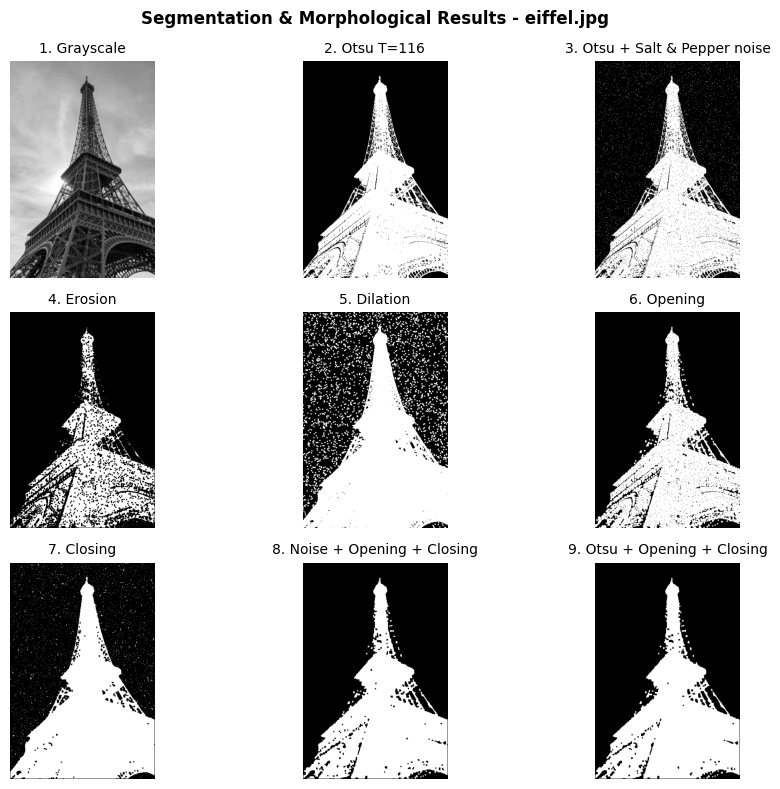

In [38]:
file_paths = ['camera.jpg', 'bird.jpg', 'eiffel.jpg']
K_SIZE = 3
INVERT = True #true jika objek lebih gelap dari latar

for idx, file_path in enumerate(file_paths, start=1):
    try:
        gray_img = convert_grayscale(file_path)
    except FileNotFoundError:
        print(f"\nFile '{file_path}' tidak ditemukan.")
        continue

    #Segmentasi
    binary_clean, otsu_t = otsu_thresholding(gray_img, invert=INVERT)

    #simulasi noise pada hasil segmentasi
    binary_noisy = saltpepper_noise(binary_clean, noise_ratio=0.04)

    #operasi morfologi pada citra dengan noise
    img_eroded   = erosion(binary_noisy, K_SIZE)
    img_dilated  = dilation(binary_noisy, K_SIZE)
    img_opened   = opening(binary_noisy, K_SIZE)
    img_closed   = closing(binary_noisy, K_SIZE)
    img_combined = opening_closing(binary_noisy, K_SIZE)

    #morfologi opening closing ke hasil segmentasi tanpa noise
    img_clean = opening_closing(binary_clean, K_SIZE)

    #tabel evaluasi
    results = {
        "Tanpa morfologi (noisy)": binary_noisy,
        "Erosion": img_eroded,
        "Dilation": img_dilated,
        "Opening": img_opened,
        "Closing": img_closed,
        "Otsu Noise + Opening + Closing": img_combined,
        "Otsu bersih + Open + Close (no noise)": img_clean,
    }

    print("\n")
    print(f"{file_path}, Otsu T={otsu_t}, kernel {K_SIZE}x{K_SIZE}")
    print(" Ground Truth = hasil Otsu tanpa noise")
    print("-" * 78)
    print(f"{'Metode':<38} | {'IoU':<7} | {'Akurasi':<8} | {'Objek(>=20px)':<13}")
    print("-" * 78)
    for name, im in results.items():
        iou, acc = calculate_metrics(im, binary_clean)
        n_obj = count_objects(im, min_area=20)
        print(f"{name:<38} | {iou:.4f}  | {acc*100:6.2f}%  | {n_obj:<13}")

    print("\n")
    fig, axes = plt.subplots(3, 3, figsize=(10, 8))
    fig.suptitle(f"Segmentation & Morphological Results - {file_path}",
                 fontsize=12, fontweight='bold')
    panels = [
        (gray_img,        "1. Grayscale"),
        (binary_clean,    f"2. Otsu T={otsu_t}"),
        (binary_noisy,    "3. Otsu + Salt & Pepper noise"),
        (img_eroded,      "4. Erosion"),
        (img_dilated,     "5. Dilation"),
        (img_opened,      "6. Opening"),
        (img_closed,      "7. Closing"),
        (img_combined,    "8. Noise + Opening + Closing"),
        (img_clean,       "9. Otsu + Opening + Closing"),#segmentasi otsu tanpa noise
    ]

    for ax, (im, title) in zip(axes.ravel(), panels):
        ax.imshow(im, cmap='gray', vmin=0, vmax=(255 if im is gray_img else 1))
        ax.set_title(title, fontsize=10)

    for ax in axes.ravel():
        ax.axis('off')

    plt.tight_layout()
    plt.show()